# Домашнее задание по теме «Ансамбли алгоритмов»

В этом домашнем задании ты самостоятельно реализуешь все те виды ансамблей алгоритмов, которые мы проходили на лекции и семинарах. Мы будем двигаться постепенно от базовых ансамблей к более продвинутым.

Тебе предстоит составить десять классов ансамблей:
- Isolation Forest в разведочном анализе данных (EDA);
- Random Forest и родственные ему ансамбли: Voting, Bagging, Pasting, Random Subspaces, Random Patches и Extra-Trees;
- Stacking и его частную версию Blending.

Выполнив задачи, ты:  
- применишь один из продвинутых методов Anomaly Detection — Isolation Forest;
- поймешь, почему для построения ансамблей так критично разнообразие базисов;
- исследуешь, как корреляция предсказаний базисов влияет на тестовые метрики;
- увидишь разницу между случайным лесом, бэггингом, пастингом и Extra-Trees на реальном датасете;
- напишешь свой класс случайного леса регрессии и модифицируешь его;
- реализуешь классы блэндинга и стэкинга, увидишь разницу между их строением.

## Разведочный анализ данных (EDA)

На каждом из семинаров мы рассматривали поведение ансамблей на задаче бинарной классификации в датасете Rain in Australia. Теперь реализуй структуру ансамблей в задаче регрессии.

В этом домашнем задании мы снова используем датасет Wine Quality.
Он содержит данные о винах Португалии региона Валенсии. В нём два отдельных файла: около 1600 записей для красного вина и почти 4900 для белого. На каждый образец приходится 11 физических и химических характеристик (фиксированная кислотность, летучая кислотность, цитрат, остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и содержание алкоголя) и целевая метка `quality` — оценка дегустатора от 0 до 10 (на практике в диапазоне ~ 3–9).

Этот датасет хорошо подходит для алгоритмов Outlier Detection. Один из них, ансамбль Isolation Forest, ты как раз и протестируешь.

Импортируй библиотеки и [загрузи Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Используй его для задачи регрессии и предскажи переменную `quality`.

In [ ]:
!pip install tqdm

In [ ]:
# Должен быть true (нужна новая версия sklearn)
import sklearn
from packaging import version
has_max_samples = version.parse(sklearn.__version__) >= version.parse("1.1")
has_max_samples

True

In [ ]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    VotingRegressor, BaggingRegressor,
    RandomForestRegressor, ExtraTreesRegressor, IsolationForest)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
from time import time

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

Теперь загрузи датасет и проведи разведочный анализ данных (EDA) и препроцессинг.

In [ ]:
# 1. Ссылки на CSV
red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

# 2. Считываем в DataFrame, указывая разделитель ';'
df_red = pd.read_csv(red_url, sep=';')
df_white = pd.read_csv(white_url, sep=';')

# 3. Добавляем колонку с типом вина
df_red["type"] = "red"
df_white["type"] = "white"

# 4. Объединяем
df = pd.concat([df_red, df_white], ignore_index=True)

# 5. Проверяем
print(df.shape)   # Сколько записей и признаков
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [ ]:
df['type'].value_counts()

,count
type,
white,4898
red,1599


In [ ]:
# Нет пропусков, один категориальный признак
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [ ]:
# Есть выбросы
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


In [ ]:
# Работаем с категориальной фичей
df = pd.get_dummies(df, columns=["type"], drop_first=True, dtype='int')  # Появится столбец type_white
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_white
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


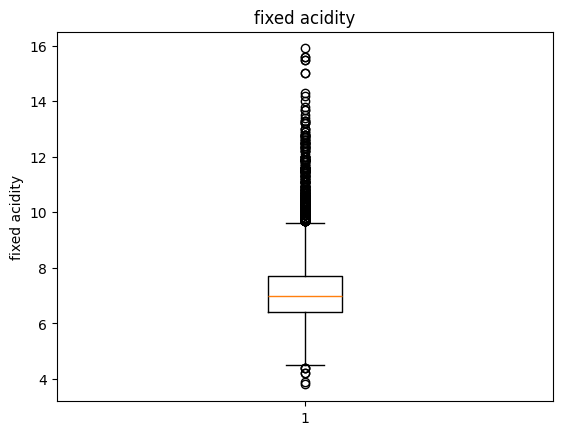

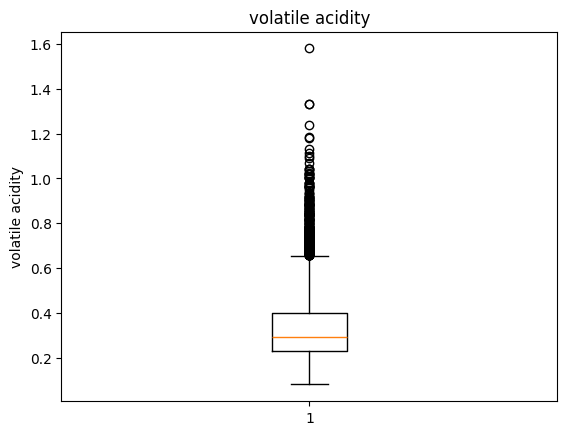

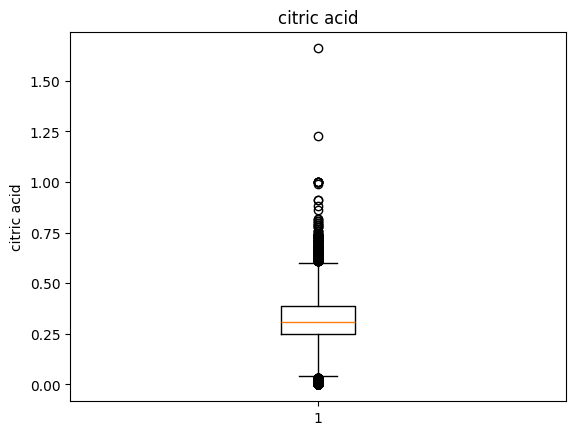

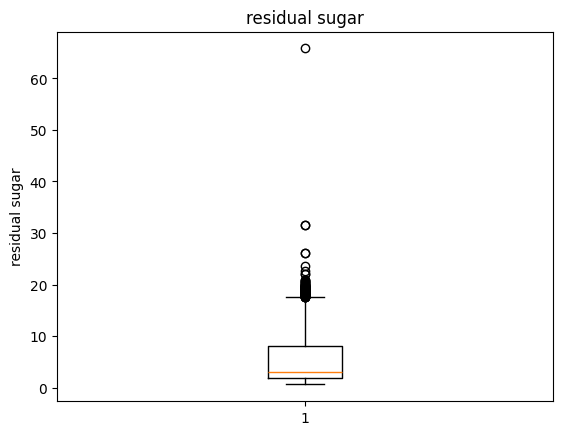

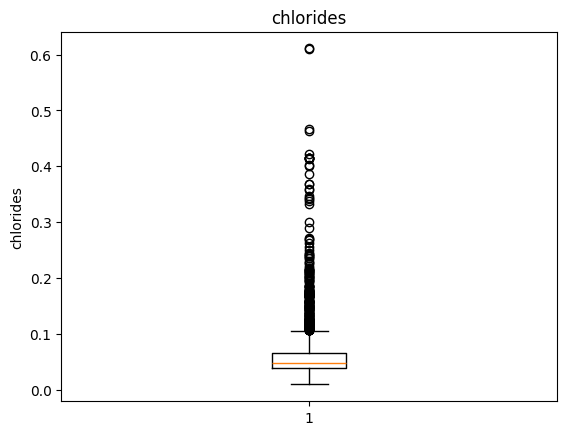

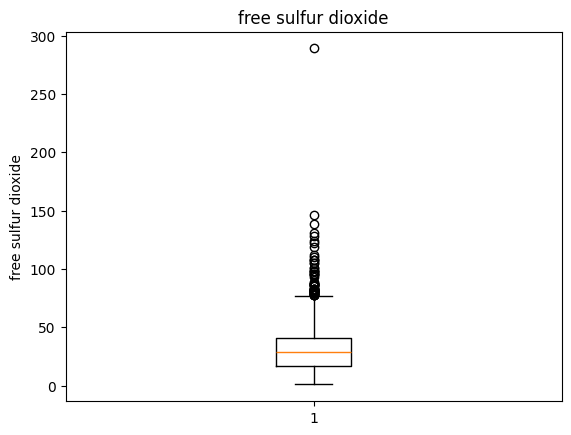

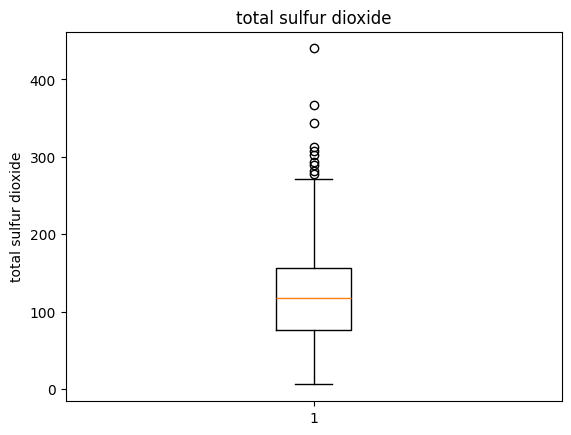

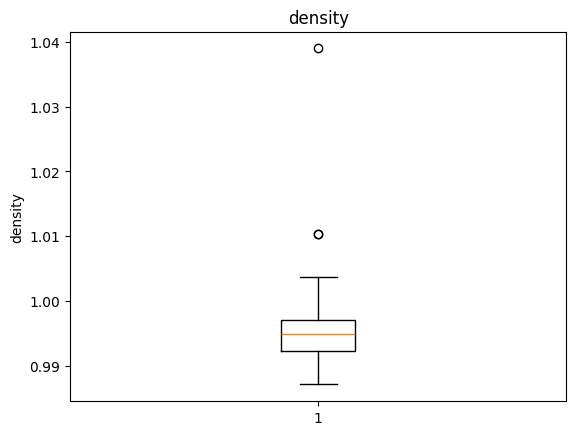

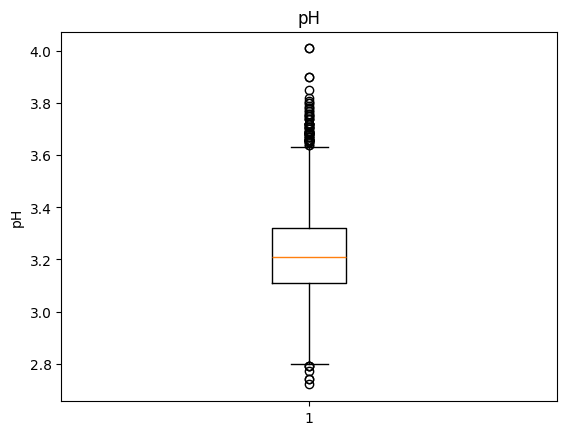

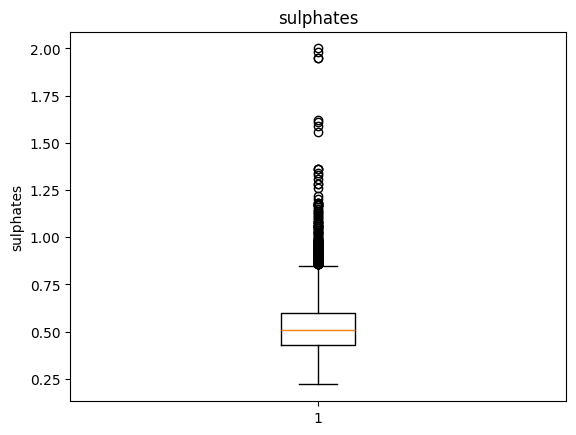

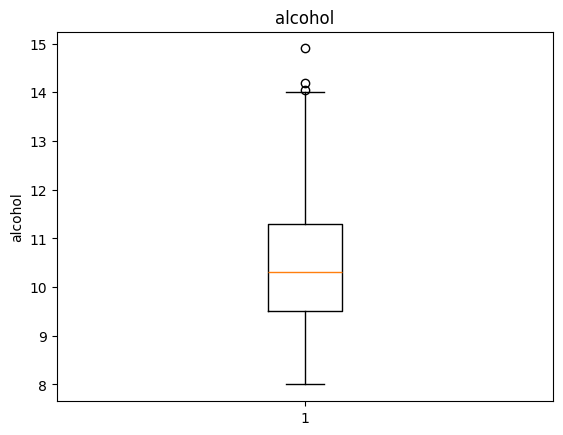

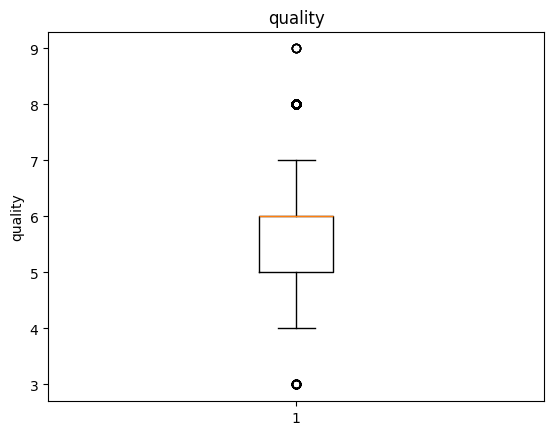

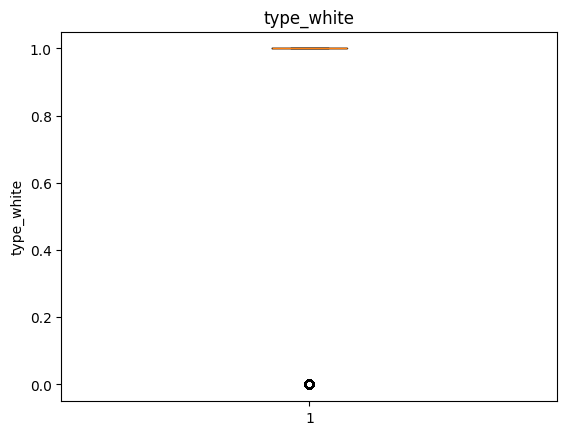

In [ ]:
# Много выбросов
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure()
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel(col)
    plt.show()

In [ ]:
X = df.drop('quality',axis=1)
y = df['quality']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
numeric = X.drop('type_white',axis=1).select_dtypes(include=['number']).columns
scaler = StandardScaler()

X_train[numeric] = scaler.fit_transform(X_train[numeric])

X_test[numeric] = scaler.transform(X_test[numeric])

В этом датасете есть как редкие значения, так и явные ошибки. Например, значение `residual sugar > 60` выбивается из других наблюдений и, скорее всего, ошибочно, так как такое количество сахара в готовом вине маловероятно.

В прошлой домашней работе мы заменяли выбросы на значения 1% и 99% перцентилей, это называется винсоризацией (*англ.* winsorization).

Ансамбль изолированного леса (*англ.* Isolation Forest) — более продвинутый метод работы с выбросами в данных, который находит экстремальные значения на основе алгоритма деревьев решений, а не просто механически «обрезает» данные.

### Задача 1. Изолированный лес [2 балла]

Цель — определить неинформативные ошибочные выбросы в датасете, чтобы их можно было убрать и улучшить качество ансамблей. Для определения выбросов используем алгоритм IsolationForest. Но есть проблема — этот алгоритм требует указания гиперпараметра `contamination`, который показывает долю выбросов в датасете. В семинаре мы использовали долю в 1%, однако на практике всегда лучше валидировать это значение.

Задача — выяснить, сколько выбросов стоит исключить из датасета: рассчитать оптимальный `contamination`.

- Проверь значения `contamination` от 0,001 до 0,1 с шагом в 0,001. Для `contamination_array` можешь использовать `numpy.linspace`.

- Обучи линейную регрессию (`lr_orig`) на наших тренировочных данных и предскажи тестовые значения (`yped_orig`). Посчитай Test MSE (`mse_orig`). [0,5 балла]

- Для каждого значения из `contamination_array` [1 балл]:
    - обучи на тренировочных данных IsolationForest с 300 базовыми деревьями, своим значением `contamination`, `random_state=42` и `n_jobs=-1`;
    - предскажи, какие наблюдения в тренировочном датасете — это выбросы; создай `X_train_clean` и `y_train_clean`, которые будут содержать только «нормальные точки» без выбросов;
    - обучи линейную регрессию (`lr_clean`) на датасете без выбросов; посчитай Test MSE этой регрессии, добавь этот Test MSE в список `mse_clean`.
- Построй график зависимости `mse_orig` и `mse_clean` от `contamination`.

  Очевидно, что `mse_orig` будет константным, в то время как `mse_clean` будет зависеть от `contamination`. Для построения `mse_orig` прямой можешь использовать `numpy.repeat`. [0,5 балла]
- Рассмотри построенный график. Есть ли в датасете ошибочные выбросы? Стоит ли избавляться от каких-то данных?

In [ ]:
# Напиши код здесь
contamination_array = np.linspace(0.001, 0.1, 100)
mse_clean = []

lr_orig =  LinearRegression()
lr_orig.fit(X_train, y_train)
# ...
ypred_orig = lr_orig.predict(X_test)
mse_orig = mean_squared_error(y_test, ypred_orig)

for i in tqdm(contamination_array):
    iso = IsolationForest(n_estimators=300,
                          contamination=i,
                          random_state=42,
                          n_jobs=-1)
    iso.fit(X_train)
    # ...
    labels_outlier = iso.predict(X_train)
    mask_normal = labels_outlier == 1
    X_train_clean = X_train[mask_normal]
    y_train_clean = y_train[mask_normal]

    lr_clean = LinearRegression()
    lr_clean.fit(X_train_clean, y_train_clean)

    # ...
    ypred_clean = lr_clean.predict(X_test)
    mse_clean.append(mean_squared_error(y_test, ypred_clean))


    # ...

  0%|          | 0/100 [00:00<?, ?it/s]

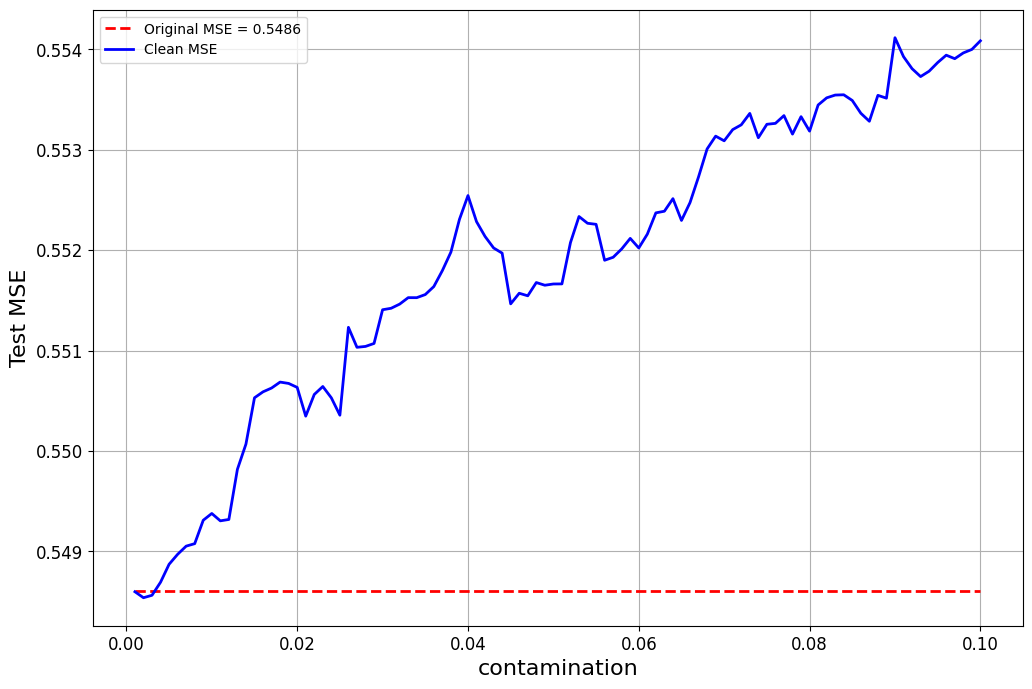

In [ ]:
# Продолжение задачи 1

# Построй график
plt.figure(figsize=(12, 8))

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# Напиши код здесь
plt.plot(contamination_array, np.repeat(mse_orig, len(contamination_array)),
         'r--', label=f'Original MSE = {mse_orig:.4f}', linewidth=2)
plt.plot(contamination_array, mse_clean, 'b-', label='Clean MSE', linewidth=2)
plt.xlabel('contamination', fontsize=16)
plt.ylabel('Test MSE', fontsize=16)
plt.legend()
plt.tick_params(axis='y')

plt.grid(True)
plt.show()

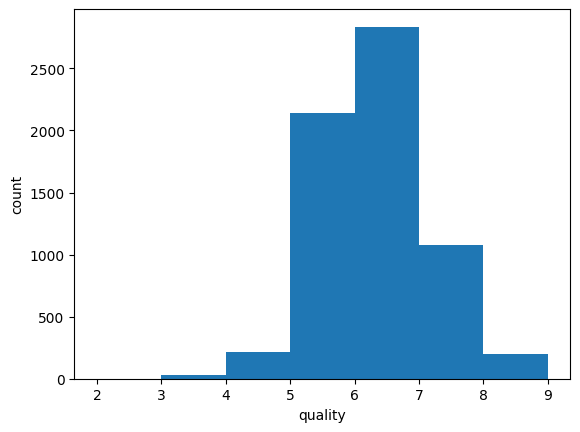

In [ ]:
# Распределение целевой
# Минимум — 4, максимум — 8
plt.hist(df["quality"], bins=range(2,10))
plt.xlabel("quality")
plt.ylabel("count")
plt.show()

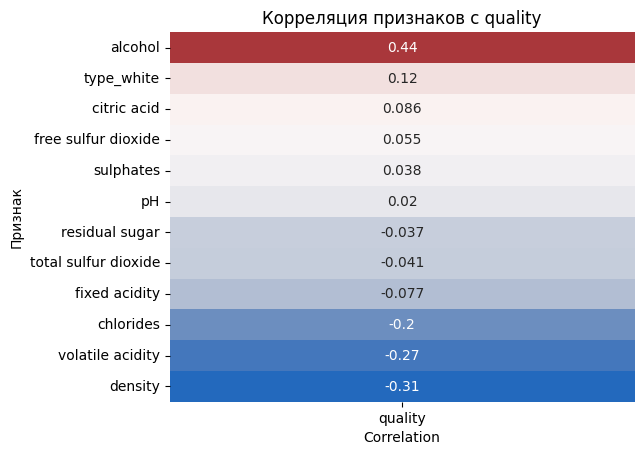

In [ ]:
# 1. Считаем матрицу корреляций
corr = df.corr(numeric_only=True)

# 2. Берём только столбец quality, убираем строку quality и сортируем
corr_q = corr["quality"].drop("quality").sort_values(ascending=False)

# 3. Рисуем теплокарту
plt.figure(figsize=(6, len(corr_q) * 0.4))
sns.heatmap(corr_q.to_frame(), annot=True, cmap="vlag", cbar=False)
plt.title("Корреляция признаков с quality")
plt.ylabel("Признак")
plt.xlabel("Correlation")
plt.show()

## Random Forest и родственные ансамбли

В этой части мы рассмотрим основные свойства и способы обучения ансамблей типа случайного леса и ему подобных (Bagging, Voting, Pasting, Extra-Trees). В анализ включим ансамбли «из коробки» (с использованием sklearn-модулей), а также будем работать с классами ансамблей, которые были реализованы на семинаре. Сейчас твоя цель — усилить эти классы с помощью различных надстроек.

Начнём с Random Forest.

### Задача 2. Корреляция базисов и метрики [1,5 балла]

Разнообразие базисных моделей — критически важное свойство любого ансамбля: оно понижает корреляцию между базисами, что в свою очередь уменьшает итоговую дисперсию ансамбля. Предлагаем убедиться в этом свойстве на примере реальных данных.

Задача — посмотреть, как гиперпараметр `max_features` влияет на тестовую MSE случайного леса. Уменьшение `max_features` приводит к тому, что базисы начинают выдавать всё более разнообразные предсказания, что уменьшает корреляцию, а значит, и тестовую ошибку.

Для каждого значения `max_features` от 1 до количества признаков в датасете выполни следующие действия.

1. Инициализируй ансамбль случайного леса со 100 базисными деревьями, соответствующий `max_features`, `random_state=42` и `n_jobs=-1`.

2. Обучи этот ансамбль на тренировочных данных из предыдущей задачи. Используй обученный ансамбль для предсказания тестового таргета. Тестовый MSE сохрани в массиве `test_mses`. [1–2 пункты — 0,5 балла]

3. Тестовая метрика найдена, теперь рассчитай корреляцию предсказаний базисов. Для начала сохрани в переменной `preds` многомерный `numpy.ndarray` массив, который будет содержать предсказания тестовых таргетов от каждого из 100 базисных деревьев. Размерность массива — (`X_test.shape[1]`, `X_test.shape[0]`). Возможно, в этом задании тебе пригодятся `list comprehension` и атрибут `rf.estimators_`.

4. Посчитай матрицу корреляций предсказаний базовых моделей. Сохрани матрицу в переменную `corr_matrix`. Подсказка: возможно, тебе пригодится функция `numpy.corrcoef()`.

5. Теперь посчитай среднюю корреляцию всех базисов друг с другом. К сожалению, если ты возьмёшь корреляцию всех значений `corr_matrix`, то в расчёт попадут диагональные элементы матрицы, которые равны единице, и это завысит среднюю корреляцию предсказаний.

      Нужно взять значения из верхнего треугольника матрицы корреляций. Чтобы это сделать, можешь воспользоваться функцией `numpy.triu_indices_from()`. Значения из верхнего треугольника сохрани в переменную `triu`.

6. Добавь в массив `mean_corrs` среднюю корреляцию базисов из `triu`. [3–6 пункты — 1 балл]

`numpy.triu_indices_from`: https://numpy.org/doc/2.1/reference/generated/numpy.triu_indices_from.html

`numpy.corrcoef`: https://numpy.org/doc/2.0/reference/generated/numpy.corrcoef.html

In [ ]:
# Варианты max_features
feature_settings = range(1, X_train.shape[1]+1)

mean_corrs = []
test_mses = []

for mf in feature_settings:
    # Напиши код здесь
    rf = RandomForestRegressor(n_estimators=100,
                               max_features=mf,
                               random_state=42,
                               n_jobs=-1)
    rf.fit(X_train, y_train)
    # ...
    y_pred = rf.predict(X_test)
    test_mses.append(mean_squared_error(y_test, y_pred))

    # Собери предсказания каждого дерева на тесте (n_trees × n_samples)
    preds = np.array([tree.predict(X_test) for tree in rf.estimators_])

    # Матрица корреляций (n_trees × n_trees)
    corr_matrix = np.corrcoef(preds)

    # Возьми только верхний треугольник без диагонали
    triu_indices = np.triu_indices_from(corr_matrix, k=1)
    triu = corr_matrix[triu_indices]
    mean_corrs.append(np.mean(triu))

Построй график и посмотри, что получилось.

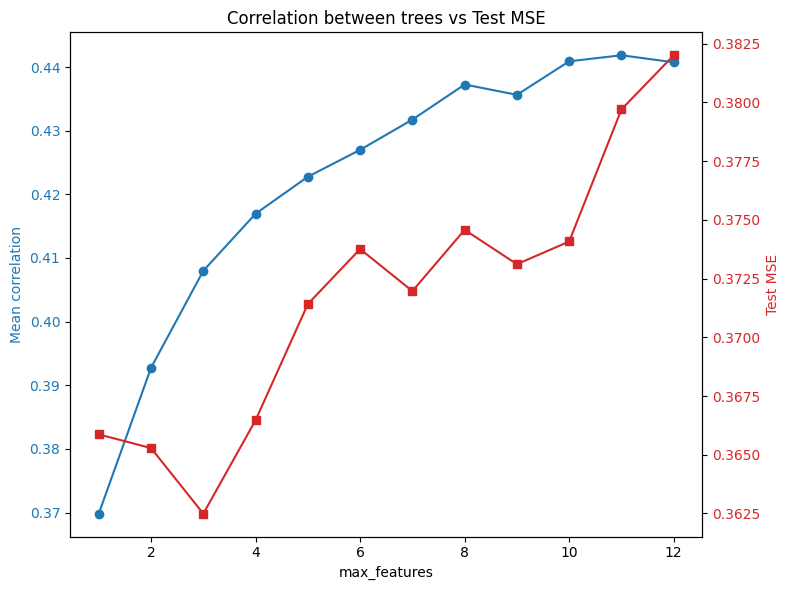

In [ ]:
# --- График ---
fig, ax1 = plt.subplots(figsize=(8,6))

ax1.plot(feature_settings, mean_corrs, marker='o', color='tab:blue', label="Mean correlation")
ax1.set_xlabel("max_features")
ax1.set_ylabel("Mean correlation", color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(feature_settings, test_mses, marker='s', color='tab:red', label="Test MSE")
ax2.set_ylabel("Test MSE", color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title("Correlation between trees vs Test MSE")
fig.tight_layout()
plt.show()

**Вопросы.** Какая зависимость между:
-  тестовой ошибкой и `max_features`;
-  `max_features` и средней корреляцией базисов;
-  между средней корреляцией и тестовой ошибкой?

Функции Test MSE и Mean Correlation — монотонно убывающие? Монотонно возрастающие? Почему?

Подсказка: возможно, чрезмерное уменьшение `max_features` может повлиять на смещение ансамбля.

Разнообразие предсказаний базисов напрямую влияет на тестовые метрики ансамбля через дисперсию и смещение. В следующей задаче рассмотрим, какие есть основные способы внедрения этого разнообразия в разных типах ансамблей.

При малых значениях max_features MSE высокое, затем снижается до оптимума, после чего может расти из за переобучения.(u образная)

Чем больше max_features, тем выше корреляция между деревьями . Больше общих признаков - более похожие деревья.(монотонно возрастающая.)

Слишком высокая корреляция увеличивает дисперсию ансамбля, слишком низкая — увеличивает смещение. Оптимальный баланс где то посередине.



### Задача 3. Зоопарк ансамблей [3 балла]

Теперь обучи на датасете все те ансамбли, которые связаны со случайным лесом и которые мы рассматривали в лонгриде, на лекции и семинарах. Сравнивать ансамбли будешь с помощью Test MSE на разных `num_estimators` (с `warm_start=True`).

- В ячейке кода ниже указаны гиперпараметры. Обрати внимание, что разные ансамбли используют разные гиперпараметры и одна из главных задач — выяснить, какой набор гиперпараметров для какого ансамбля релевантен.

    Например, в одном ансамбле может использоваться `max_features=feature_frac`, а в другом — `max_features=1.0`. Другой пример: где-то — `bootstrap=True`, где-то — `False`.

>**Важно.** Гиперпараметр `max_samples=sample_frac` одинаковый для всех ансамблей.

- Базовая модель всех ансамблей — это неограниченное дерево регрессии.

- Используя различные гиперпараметры, а также `n_jobs=-1`, инициализируй ансамбли (пока без обучения) [1,5 балла]:
    - Bagging,
    - Pasting,
    - Random Subspaces,
    - Random Patches,
    - Random Forest,
    - Extra-Trees (`bootstrap=True`).

- Теперь инициализируй ансамбль Voting, используя три базовые модели:
    - линейную регрессию;
    - kNN (15 соседей);
    - SVR (`C=3.0`, `epsilon=0.1`).

- Обучи Voting на обучающей выборке и используй его для предсказания тестовых данных. Замерь время обучения и предсказания (можешь использовать `time()`). В переменных `voting_mse` и `voting_time` сохрани значения Test mse, времени обучения и предсказания ансамбля Voting. [Правильная инициализация, обучение и предсказание Voting — 0,5 балла.]

- Инициализируй цикл: для каждого значения `num_estimators` из заданного массива обучи каждый из ансамблей (кроме Voting) и предскажи тестовые таргеты. Замерь время обучения и предсказания с помощью функции `time()`. Для каждого ансамбля и каждого значения `num_estimators` сохрани тестовую MSE предсказаний и время обучения, а также предсказания в словари `mse_logs` и `time_logs` соответственно. [Правильная инициализация цикла — 1 балл.]

- Гиперпараметр `warm_start=True` позволит увеличивать `num_estimators` «на ходу», без необходимости каждый раз переобучивать ансамбль на увеличивающихся значениях `num_estimators`.



In [ ]:
# ==== Гиперпараметры ====
start_n = 12        # начальное количество базисов
step_n = 12         # шаг на итерацию
rounds = 15         # сколько раз увеличиваем n_estimators (итого до 180)
sample_frac = 0.7   # доля объектов на базовую модель
feature_frac = 0.4  # доля признаков на базовую модель
warm_start=True
rs = 42             # random_state

# n значений
n_values = list(range(start_n, start_n + rounds*step_n, step_n))

# Напиши код здесь

# ==== Базовая модель ====

base_tree = DecisionTreeRegressor(random_state=rs)

# ==== Ансамбли ====

bagging = BaggingRegressor(estimator=base_tree,
                           n_estimators=start_n,
                           max_samples=sample_frac,
                           bootstrap=True,
                           max_features=1.0,
                           warm_start=warm_start,
                           random_state=rs,
                           n_jobs=-1)

pasting = BaggingRegressor(estimator=base_tree,
                           n_estimators=start_n,
                           max_samples=sample_frac,
                           bootstrap=False,
                           max_features=1.0,
                           warm_start=warm_start,
                           random_state=rs,
                           n_jobs=-1)

subspaces = BaggingRegressor(estimator=base_tree,
                             n_estimators=start_n,
                             max_samples=1.0,
                             bootstrap=False,
                             max_features=feature_frac,
                             warm_start=warm_start,
                             random_state=rs,
                             n_jobs=-1)

patches = BaggingRegressor(estimator=base_tree,
                           n_estimators=start_n,
                           max_samples=sample_frac,
                           bootstrap=True,
                           max_features=feature_frac,
                           warm_start=warm_start,
                           random_state=rs,
                           n_jobs=-1)

rf = RandomForestRegressor(n_estimators=start_n,
                           max_samples=sample_frac,
                           bootstrap=True,
                           max_features=feature_frac,
                           warm_start=warm_start,
                           random_state=rs,
                           n_jobs=-1)

extratrees = ExtraTreesRegressor(n_estimators=start_n,
                                 max_samples=sample_frac,
                                 bootstrap=True,
                                 max_features=feature_frac,
                                 warm_start=warm_start,
                                 random_state=rs,
                                 n_jobs=-1)

models = {
    "bagging":    bagging,
    "pasting":    pasting,
    "subspaces":  subspaces,
    "patches":    patches,
    "rf":         rf,
    "extratrees": extratrees,
}

# Напиши код здесь

# ==== VotingRegressor (независим от n_estimators) ====
voting = VotingRegressor([('lr', LinearRegression()),
                          ('knn', KNeighborsRegressor(n_neighbors=15)),
                          ('svr', SVR(C=3.0, epsilon=0.1))])

t0 = time()
voting.fit(X_train, y_train)
y_pred_v = voting.predict(X_test)
t1 = time()
voting_mse = mean_squared_error(y_test, y_pred_v)
voting_time = t1 - t0

# === Логи ===
mse_logs = {name: [] for name in models}
time_logs = {name: [] for name in models}
# добавим ключи для voting (заполним после цикла константами)
mse_logs["voting"] = []
time_logs["voting"] = []

# Напиши код здесь

# === Цикл по num_estimators ===
for _ in tqdm(range(rounds)):
    # обучаем и мерим для каждого ансамбля
    for name, mdl in models.items():
        t0 = time()
        mdl.fit(X_train, y_train)
        y_pred = mdl.predict(X_test)
        t1 = time()

        mse_logs[name].append(mean_squared_error(y_test, y_pred))
        time_logs[name].append(t1 - t0)

        # добавляем ещё базисов
        mdl.n_estimators += step_n


  0%|          | 0/15 [00:00<?, ?it/s]

Сгенерируй графики полученных тестовых MSE и времени обучения + предсказания.

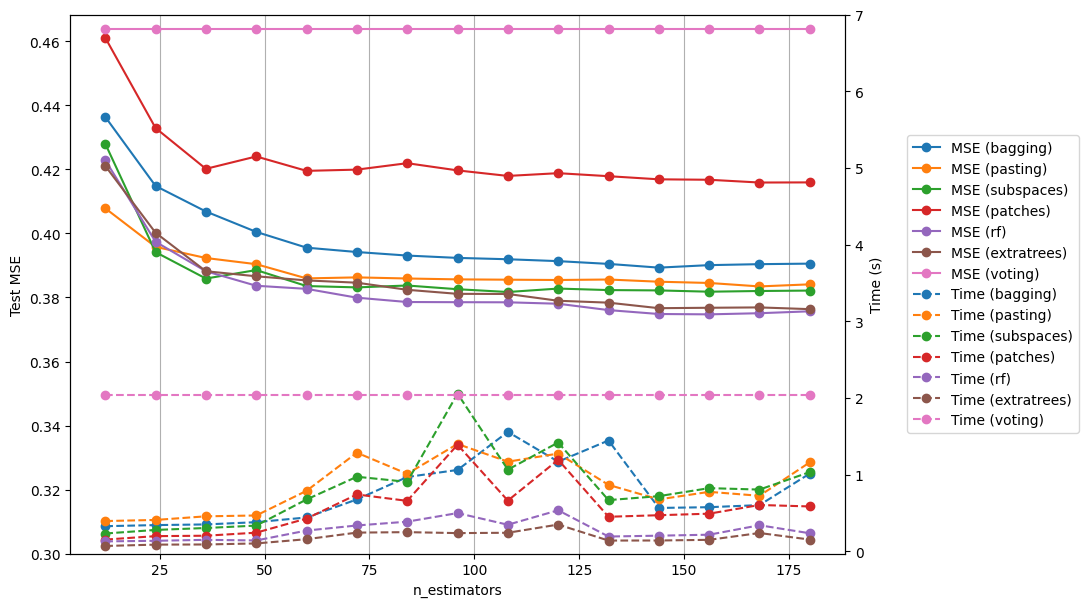

In [ ]:
# Заполняем voting константами той же длины, что и n_values
mse_logs["voting"] = [voting_mse] * len(n_values)
time_logs["voting"] = [voting_time] * len(n_values)

# === График MSE и времени ===
fig, ax1 = plt.subplots(figsize=(10, 7))

# --- Первая ось: MSE ---
for name, mses in mse_logs.items():
    ax1.plot(n_values, mses, marker='o', label=f"MSE ({name})")
ax1.set_xlabel("n_estimators")
ax1.set_ylabel("Test MSE")
ax1.set_ylim(0.3, None)
ax1.tick_params(axis='y')
ax1.grid(axis='x')

# --- Вторая ось: время ---
ax2 = ax1.twinx()
for name, times in time_logs.items():
    ax2.plot(n_values, times, linestyle='dashed', marker='o', label=f"Time ({name})")
ax2.set_ylabel("Time (s)")
ax2.set_ylim(None, 7)
ax2.tick_params(axis='y')

# --- Легенда за пределами графика ---
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center left",
    bbox_to_anchor=(1.08, 0.5),
    borderaxespad=0.
)

plt.show()

**Вопросы.** Какой ансамбль показал себя лучше всего с точки зрения тестовой метрики? А какой ансамбль с точки зрения времени обучения и предсказания? Почему?

Random Forest — оптимальный выбора, так как он показывает лучшее качество, имеет приемлемое время обучения, хорошо обобщает благодаря двойной рандомизации

Завершаем анализ sklearn-ансамблей «из коробки». В следующих задачах тебе предстоит написать свои классы ансамблей.

### Задача 4. Свой класс леса регрессии [1,5 балла]

На семинаре мы собирали класс случайного леса классификации, который далее использовали для предсказания меток в задаче бинарной классификации. Теперь нужно сконструировать класс случайного леса регрессии.

Используя класс леса классификации с семинара, инициализируй класс леса регрессии.

Не нужно реализовывать дополнительный функционал и добавлять новые гиперпараметры и инструментарий в класс (не добавляй то, чего не было на семинаре).

За новую метрику возьми MSE (на семинаре был `accuracy`).

Подсказка: класс леса регрессии очень схож с классом леса классификации, но есть несколько ключевых отличий.

In [ ]:
class MyRandomForestRegressor:
    def __init__(self, n_estimators=100, max_samples=1.0, bootstrap=True,
                 max_features=1.0, random_state=42, base_estimator_params=None):
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.bootstrap = bootstrap
        self.max_features = max_features
        self.random_state = random_state
        self.base_estimator_params = base_estimator_params or {}
        self.estimators_ = []
        self.features_ = []

        if random_state is not None:
            np.random.seed(random_state)

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        n_samples, n_features = X.shape

        if isinstance(self.max_features, float):
            n_feat_select = max(1, int(self.max_features * n_features))
        else:
            n_feat_select = self.max_features

        if isinstance(self.max_samples, float):
            n_samp_select = max(1, int(self.max_samples * n_samples))
        else:
            n_samp_select = self.max_samples

        self.estimators_ = []
        self.features_ = []

        for i in range(self.n_estimators):
            if self.bootstrap:
                indices = np.random.choice(n_samples, size=n_samp_select, replace=True)
            else:
                indices = np.random.choice(n_samples, size=n_samp_select, replace=False)

            X_sample = X[indices]
            y_sample = y[indices]

            feat_indices = np.random.choice(n_features, size=n_feat_select, replace=False)
            X_sample = X_sample[:, feat_indices]

            tree = DecisionTreeRegressor(**self.base_estimator_params)
            tree.fit(X_sample, y_sample)

            self.estimators_.append(tree)
            self.features_.append(feat_indices)

        return self

    def predict(self, X):
        X = np.asarray(X)
        predictions = np.zeros((X.shape[0], len(self.estimators_)))

        for i, (tree, feats) in enumerate(zip(self.estimators_, self.features_)):
            predictions[:, i] = tree.predict(X[:, feats])

        return predictions.mean(axis=1)

Оцени качество класса леса регрессии на тех же гиперпараметрах, что из предыдущей задачи обучения леса, с помощью sklearn-класса.

In [ ]:
rf = MyRandomForestRegressor(
    n_estimators=180,
    max_samples=0.7,
    bootstrap=True,
    max_features=0.6,
    random_state=45,
    base_estimator_params={"max_depth": None, "min_samples_leaf": 1}
)

rf.fit(X_train, y_train)

In [ ]:
# MSE нашего класса
y_pred = rf.predict(X_test)
print("My RF MSE :", mean_squared_error(y_test, y_pred))

My RF MSE : 0.3860971668249446


In [ ]:
# MSE класса sklearn
print("Sklearn RF MSE :", mse_logs['rf'][-1])

Sklearn RF MSE : 0.37568121240899016


**Вопрос.** Какой класс показал лучшие метрики качества?
Поставь `random_state=45` в `MyRandomForestRegressor` выше и обучись вновь. Теперь какой класс выигрывает — твой или из sklearn?

### Задача 5. Модификация класса леса регрессии [1 балл]

Построенный класс — базовый и фундаментальный. Теперь разнообразь его функционал.

Добавь метод `feature_importances_`, который будет рассчитывать важности признаков в датасете (MDI) и выдавать массив важностей для каждого признака.

Подсказки
- Преврати этот метод в аттрибут класса с помощью декоратора `@property`.
- Возможно, тебе пригодится `self.estimators_`.
- Не забудь проверять на случай, когда у нас нет базовых моделей в ансамбле вообще. В таком случае верни `None`.

In [ ]:
class MyRandomForestRegressor(MyRandomForestRegressor):
    @property
    def feature_importances_(self):
        if not self.estimators_:
            return None

        n_features = X_train.shape[1]
        importances = np.zeros(n_features)

        for tree, feats in zip(self.estimators_, self.features_):
            tree_importances = tree.feature_importances_
            for i, feat_idx in enumerate(feats):
                importances[feat_idx] += tree_importances[i]

        importances /= len(self.estimators_)
        return importances
    def score(self, X, y):
        from sklearn.metrics import r2_score
        y_pred = self.predict(X)
        return r2_score(y, y_pred)

Реализуй MDI на нашем датасете и посмотри, что получилось.

In [ ]:
rf = MyRandomForestRegressor(
    n_estimators=180,
    max_samples=0.7,
    bootstrap=True,
    max_features=0.6,
    random_state=45,
    base_estimator_params={"max_depth": None, "min_samples_leaf": 1}
)

rf.fit(X_train, y_train)

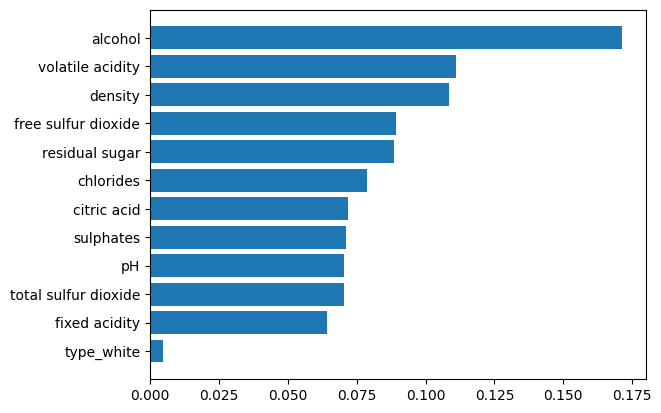

In [ ]:
fi = pd.DataFrame({'column': X_train.columns, 'feature_importance': rf.feature_importances_})
fi = fi.sort_values('feature_importance',ascending=True)
plt.barh(fi['column'], fi['feature_importance']);

Теперь реализуй стороннюю sklearn-функцию `permutation_importance`, которая также рассчитывает значения важности признаков, но уже с помощью метода MDA.

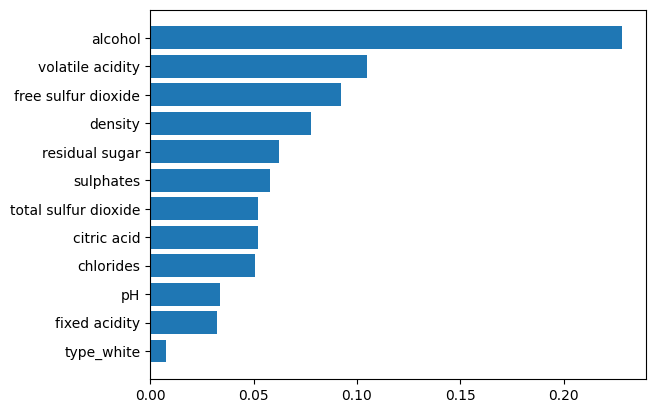

In [ ]:
from sklearn.inspection import permutation_importance

# Считаем permutation importance
result = permutation_importance(
    rf,
    X_test.values,
    y_test.values,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

fi = pd.DataFrame({'column': X_train.columns, 'feature_importance': abs(result.importances_mean)})
fi = fi.sort_values('feature_importance')
plt.barh(fi['column'], fi['feature_importance']);

**Вопрос.** Сильно ли отличаются результаты MDA, написанного вручную, от MDA из sklearn?

## Stacking & Blending

Случайный лес и родственные ему ансамбли строят большое количество одинаковых базовых моделей. Каждая из них «слабая», но в то же время вместе они формируют сильную композицию, которая получается из простой функции усреднения предсказаний базисов.

Блендинг и его обобщённая версия стекинг, напротив, строят несколько самих по себе сильных (самодостаточных) моделей. Их предсказания агрегирует мета-модель второго уровня, которая, в свою очередь, находит сильные и слабые стороны каждой из базовых моделей. Мета-модель комбинирует предсказания базисов в зависимости от того, на каком участке данных тот или иной базис выдаёт качественные предсказания.

На семинаре мы рассмотрели, как работают блендинг и стекинг в задаче классификации: как вручную построить эти два ансамбля и как можно использовать sklearn-классы «из коробки». Однако мы не анализировали, как строить блендинг и стекинг в задаче регрессии, и не предлагали написать свои классы блендинга и стекинга — в этом и будет твоя задача в этой части задания.

### Задача 6. Свой класс блендинга регрессии [1,5 балла]

Построй свой класс блендинга регрессии, используя то, что мы изучили на семинаре. Класс будет базовым и в то же время фундаментальным: нам нужно будет реализовать два метода `fit()` и `predict()`.
- Раздели train и holdout.
- Обучи базовые модели на `X_tr`.
- Получи их предсказания на `X_blend`.
- На этих предсказаниях обучи мета-модель (по умолчанию будет линейная регрессия).
- На тесте используй те же базовые модели (обученные на `X_tr`) без дообучения на всём train.

In [ ]:
class MyBlendingRegressor:

    "Простой блендинг по holdout валидации"

    def __init__(self, base_models: dict, meta_model=None,
                 test_size=0.3, random_state=42, shuffle=True):
        self.base_models = base_models
        self.meta_model = meta_model if meta_model is not None else LinearRegression()
        self.test_size = test_size
        self.random_state = random_state
        self.shuffle = shuffle            # для разбиения на train и blend

        self.model_order_ = list(base_models.keys())
        self.fitted_base_ = None
        self.meta_model_ = None

    def fit(self, X, y):

        # Напиши код здесь

        # holdout сплит
        X_tr, X_blend, y_tr, y_blend = train_test_split(
            X, y, test_size=self.test_size,
            random_state=self.random_state, shuffle=self.shuffle
        )

        # Обучаем базовые на X_tr
        self.fitted_base_ = {}
        for name, model in self.base_models.items():
            self.fitted_base_[name] = clone(model).fit(X_tr, y_tr)

        # Матрица предсказаний на holdout
        P_blend = np.column_stack([
            self.fitted_base_[name].predict(X_blend)
            for name in self.model_order_
        ])

        # Мета-модель на holdout-предсказаниях
        self.meta_model_ = clone(self.meta_model).fit(P_blend, y_blend)

        return self

    def predict(self, X):

        # предсказания базовых (обученных на X_tr)
         P = np.column_stack([self.fitted_base_[name].predict(X)
                              for name in self.model_order_])

         return self.meta_model_.predict(P)

Посмотри на эффективность. Используй шесть базовых моделей, на которых будет строиться блендинг: Ridge- и LASSO-регрессии, SVR, kNN, Random Forest, Extra-Trees. Измерь тестовую MSE.

In [ ]:
base = {
    "ridge": Ridge(alpha=1.0),
    "lasso": Lasso(alpha=0.001, max_iter=5000),
    "svr":   SVR(C=3.0, epsilon=0.1),
    "knn":   KNeighborsRegressor(n_neighbors=15),
    "rf":    RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "et":    ExtraTreesRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

# Blending
blend = MyBlendingRegressor(base_models=base, meta_model=LinearRegression(),
                            test_size=0.3, random_state=42, shuffle=True)
blend.fit(X_train, y_train)
y_pred_blend = blend.predict(X_test)
print("Blending MSE:", mean_squared_error(y_test, y_pred_blend))

Blending MSE: 0.3784913028272366


**Вопрос.** Сравни качество получившегося блендинга и случайного леса из предыдущих задач. Какая из моделей показывает лучшее качество и почему?

они практически одинаковые

Теперь перейдём к обобщённой задаче и построению класса стекинга регрессии, который зачастую показывает лучшие метрики качества, чем блендинг (хотя и обучается дольше по времени).

### Задача 7. Свой класс стекинга регрессии [1,5 балла]

Построй класс стекинга регрессии.

Ключевые отличия стекинга от блендинга:
*  вместо holdout используем KFold и OOF-признаки (`cross_val_predict`);
*  мета-модель учим на OOF-матрице `Z_tr`;
*  доучиваем базовые на всём train (для инференса).

In [ ]:
class MyStackingRegressor:

    "OOF-стекинг для регрессии"

    def __init__(self, base_models: dict, meta_model=None,
                 cv=5, random_state=42):
        self.base_models = base_models
        self.meta_model = meta_model if meta_model is not None else LinearRegression()
        self.cv = cv
        self.random_state = random_state

        self.model_order_ = list(base_models.keys())
        self.fitted_base_ = None
        self.meta_model_ = None

    def fit(self, X, y):
        # Напиши код здесь
        X = np.asarray(X)
        y = np.asarray(y)
        n_samples = X.shape[0]
        n_models = len(self.base_models)
        # Различие 1: KFold + OOF вместо hold-out
        kf = KFold(n_splits=self.cv, shuffle=True, random_state=self.random_state)

        # Собираем OOF-матрицу Z_tr: (n_train, M)
        Z_tr = np.zeros((n_samples, n_models))

        for j, name in enumerate(self.model_order_):
            model = clone(self.base_models[name])

            # Возвращаем OOF-предсказания базовой модели
            Z_tr[:, j] = cross_val_predict(model, X, y, cv=kf, n_jobs=-1)

        # Различие 2: учим мета-модель на OOF
        self.meta_model_ = clone(self.meta_model).fit(Z_tr, y)

        # Различие 3: дообучаем базовые на всём train (можешь использовать dict comprehension)
        self.fitted_base_ = {}
        for name, model in self.base_models.items():
            self.fitted_base_[name] = clone(model).fit(X, y)

        return self

    def predict(self, X):

        # Формируем тестовую матрицу предсказаний базовых (refit на всём train)
        P = np.column_stack([self.fitted_base_[name].predict(X)
                             for name in self.model_order_])

        return self.meta_model_.predict(P)

Также попробуй оценить качество.

In [ ]:
base = {
    "ridge": Ridge(alpha=1.0),
    "lasso": Lasso(alpha=0.001, max_iter=5000),
    "svr":   SVR(C=3.0, epsilon=0.1),
    "knn":   KNeighborsRegressor(n_neighbors=15),
    "rf":    RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "et":    ExtraTreesRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

# Stacking (OOF)
stack = MyStackingRegressor(base_models=base, meta_model=LinearRegression(),
                            cv=5, random_state=42)
stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)
print("Stacking MSE:", mean_squared_error(y_test, y_pred_stack))

Stacking MSE: 0.3455853351316479


**Вопрос.** Сравни качество стекинга, блендинга и ансамблей из предыдущей части домашней работы. Какой ансамбль показывает лучшее качество? Почему?

стекинг лучше, потому что присутствует разнообразие моделей, модель автоматически находит лучшие веса для базисов